Mount Google Drive to access the data files.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Locate the file path for App_Sessions.csv within Google Drive.

In [2]:
import os
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'App_Sessions' in file:
            print(os.path.join(root, file))

/content/drive/MyDrive/App_Sessions.csv


Load App_Sessions data, parse timestamps, and sort by player and time.

In [3]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/App_Sessions.csv', low_memory=False)
df['Event_time'] = pd.to_datetime(df['Event_time'], utc=True)
df = df.sort_values(['pid', 'Event_time'])

print("Total rows:", len(df))
print("Unique players:", df['pid'].nunique())
id_cols = ['pid', 'Advertising_ID', 'Amazon_Fire_ID', 'Android_ID', 'IDFA', 'IDFV', 'OAID']
print(df.drop(columns=id_cols)[['Event_time', 'App_name', 'Event_name', 'Platform']].head())

Total rows: 714857
Unique players: 186
                     Event_time    App_name Event_name Platform
19657 2022-02-01 06:25:01+00:00  Pokémon GO     launch  android
19658 2022-02-01 19:30:06+00:00  Pokémon GO     launch  android
19659 2022-02-01 20:14:18+00:00  Pokémon GO     launch  android
19660 2022-02-01 22:08:52+00:00  Pokémon GO     launch  android
19661 2022-02-01 22:54:06+00:00  Pokémon GO     launch  android


Inspect the column names of the raw dataset.

In [4]:
print(df.columns.tolist())

['pid', 'Event_time', 'ATT', 'Advertising_ID', 'Amazon_Fire_ID', 'Android_ID', 'App_name', 'App_version', 'Channel', 'Conversion_type', 'Cost_currency', 'Country_code', 'Device_category', 'Device_model', 'Device_type', 'Event_name', 'IDFA', 'IDFV', 'Language', 'OAID', 'OS_version', 'Operator', 'Platform', 'SDK_version', 'State']


Calculate initial player-level features (playCount, activeDuration, recency, avg_interval) and use a 30-day threshold as the initial churn definition.


In [5]:
reference_date = df['Event_time'].max()

features = df.groupby('pid').agg(
    playCount=('Event_time', 'count'),
    first_session=('Event_time', 'min'),
    last_session=('Event_time', 'max')
).reset_index()

# activeDuration
features['activeDuration'] = (
    features['last_session'] - features['first_session']
).dt.total_seconds() / 86400

# recency
features['recency'] = (
    reference_date - features['last_session']
).dt.total_seconds() / 86400

# inter-session interval
df['prev_time'] = df.groupby('pid')['Event_time'].shift(1)
df['interval'] = (df['Event_time'] - df['prev_time']).dt.total_seconds() / 86400
avg_interval = df.groupby('pid')['interval'].mean().reset_index()
avg_interval.columns = ['pid', 'avg_interval']

features = features.merge(avg_interval, on='pid')

# define churn label
features['churn'] = (features['recency'] > 30).astype(int)

print("Players:", len(features))
print("\nChurn distribution:")
print(features['churn'].value_counts())
print(f"Churn rate: {features['churn'].mean():.1%}")
print("\n", features[['playCount', 'activeDuration', 'recency', 'avg_interval']].describe())

Players: 186

Churn distribution:
churn
1    127
0     59
Name: count, dtype: int64
Churn rate: 68.3%

           playCount  activeDuration     recency  avg_interval
count    186.000000      186.000000  186.000000    186.000000
mean    3843.317204      941.980555  111.381250      4.657091
std     5377.177771      390.292701  143.792634     16.394188
min        5.000000        0.010752    0.000000      0.002150
25%      362.250000      737.403093   10.086510      0.163446
50%     1531.500000     1112.598600   43.145897      0.546974
75%     4846.750000     1254.479167  164.039543      1.572347
max    31230.000000     1298.270023  998.480336    141.490729


Initial model: includes recency as a feature. This caused data leakage because churn is defined using recency. The issue is corrected in the next cell.


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import numpy as np

feature_cols = ['playCount', 'activeDuration', 'recency', 'avg_interval']
X = features[feature_cols]
y = features['churn']

# Cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
print("Random Forest AUC:", rf_scores.mean().round(3), "±", rf_scores.std().round(3))

# Logistic Regression
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
lr = LogisticRegression(random_state=42, max_iter=1000)
lr_scores = cross_val_score(lr, X_scaled, y, cv=cv, scoring='roc_auc')
print("Logistic Regression AUC:", lr_scores.mean().round(3), "±", lr_scores.std().round(3))

Random Forest AUC: 0.998 ± 0.004
Logistic Regression AUC: 1.0 ± 0.0


Corrected model: recency was removed to avoid the data leakage identified above.

In [7]:
# remove recency
feature_cols = ['playCount', 'activeDuration', 'avg_interval']
X = features[feature_cols]
y = features['churn']

# Random Forest
rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
print("Random Forest AUC:", rf_scores.mean().round(3), "±", rf_scores.std().round(3))

# Logistic Regression
X_scaled = scaler.fit_transform(X)
lr_scores = cross_val_score(lr, X_scaled, y, cv=cv, scoring='roc_auc')
print("Logistic Regression AUC:", lr_scores.mean().round(3), "±", lr_scores.std().round(3))

Random Forest AUC: 0.829 ± 0.054
Logistic Regression AUC: 0.541 ± 0.072


Add break_count and max_gap as additional behavioural features, then retrain.

In [8]:
# add more features
# break count
df['gap_over_7'] = (df['interval'] > 7).astype(int)
break_count = df.groupby('pid')['gap_over_7'].sum().reset_index()
break_count.columns = ['pid', 'break_count']
features = features.merge(break_count, on='pid')

# max gap:
max_gap = df.groupby('pid')['interval'].max().reset_index()
max_gap.columns = ['pid', 'max_gap']
features = features.merge(max_gap, on='pid')

# new features to run
feature_cols = ['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap']
X = features[feature_cols]
y = features['churn']

rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
print("Random Forest AUC:", rf_scores.mean().round(3), "±", rf_scores.std().round(3))

X_scaled = scaler.fit_transform(X)
lr_scores = cross_val_score(lr, X_scaled, y, cv=cv, scoring='roc_auc')
print("Logistic Regression AUC:", lr_scores.mean().round(3), "±", lr_scores.std().round(3))

Random Forest AUC: 0.805 ± 0.063
Logistic Regression AUC: 0.597 ± 0.07


Full classification report (precision, recall, F1) for the 5-feature model.

In [9]:
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict

feature_cols = ['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap']
X = features[feature_cols]
y = features['churn']

# Random Forest
y_pred_rf = cross_val_predict(rf, X, y, cv=cv)
print("=== Random Forest ===")
print(classification_report(y, y_pred_rf))

# Logistic Regression
X_scaled = scaler.fit_transform(X)
y_pred_lr = cross_val_predict(lr, X_scaled, y, cv=cv)
print("=== Logistic Regression ===")
print(classification_report(y, y_pred_lr))

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.73      0.56      0.63        59
           1       0.82      0.91      0.86       127

    accuracy                           0.80       186
   macro avg       0.77      0.73      0.75       186
weighted avg       0.79      0.80      0.79       186

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       1.00      0.02      0.03        59
           1       0.69      1.00      0.81       127

    accuracy                           0.69       186
   macro avg       0.84      0.51      0.42       186
weighted avg       0.79      0.69      0.57       186



Compare 7, 14, 30, and 60-day churn thresholds. The 60-day threshold was selected for the final model. Source of Table III in the dissertation.  

In [10]:
# compare different threshold
feature_cols = ['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap']

for threshold in [7, 14, 30, 60]:
    features['churn'] = (features['recency'] > threshold).astype(int)
    X = features[feature_cols]
    y = features['churn']

    rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
    print(f"Threshold {threshold} days | Churn rate: {y.mean():.1%} | RF AUC: {rf_scores.mean():.3f} ± {rf_scores.std():.3f}")

Threshold 7 days | Churn rate: 88.2% | RF AUC: 0.575 ± 0.095
Threshold 14 days | Churn rate: 69.4% | RF AUC: 0.773 ± 0.053
Threshold 30 days | Churn rate: 68.3% | RF AUC: 0.805 ± 0.063
Threshold 60 days | Churn rate: 42.5% | RF AUC: 0.870 ± 0.034


Load InAppPurchases data.

In [11]:
iap = pd.read_csv('/content/drive/MyDrive/InAppPurchases.csv', low_memory=False)
print("Shape:", iap.shape)
print("Columns:", iap.columns.tolist())
print(iap.drop(columns=['pid']).head(3))

Shape: (326925, 6)
Columns: ['pid', 'Change in pokecoins', 'Date and time', 'Item purchased', 'Number of items', 'Type of activity']
   Change in pokecoins            Date and time Item purchased  \
0                  NaN  07/08/2025 09:37:33 UTC     Poke balls   
1                  NaN  06/27/2025 23:35:37 UTC         Potion   
2                  NaN  07/08/2025 09:37:33 UTC    Great balls   

   Number of items     Type of activity  
0              1.0  In-game item bought  
1              1.0  In-game item bought  
2              3.0  In-game item bought  


Compute purchase-related features: total_transactions, unique_items, total_coins_spent, and an exploratory is_payer indicator.

In [12]:

iap['Date and time'] = pd.to_datetime(iap['Date and time'], utc=True)


paid = iap[iap['Change in pokecoins'] < 0]

iap_features = iap.groupby('pid').agg(
    total_transactions=('Item purchased', 'count'),
    unique_items=('Item purchased', 'nunique'),
    total_coins_spent=('Change in pokecoins', lambda x: x[x < 0].sum())
).reset_index()


real_purchase = iap[iap['Type of activity'] == 'PokeCoin purchase'].groupby('pid').size().reset_index()
real_purchase.columns = ['pid', 'real_purchase_count']

iap_features = iap_features.merge(real_purchase, on='pid', how='left')
iap_features['real_purchase_count'] = iap_features['real_purchase_count'].fillna(0)
iap_features['is_payer'] = (iap_features['real_purchase_count'] > 0).astype(int)

print(iap_features.shape)
print(iap_features.drop(columns=['pid']).head())
print("\nPayers vs Non-payers:")
print(iap_features['is_payer'].value_counts())

(181, 6)
   total_transactions  unique_items  total_coins_spent  real_purchase_count  \
0                5441            53          -117839.0                  0.0   
1               10386            45          -208350.0                  0.0   
2                5865            63          -317675.0                  0.0   
3                 280            21             -789.0                  0.0   
4                  47            14             -403.0                  0.0   

   is_payer  
0         0  
1         0  
2         0  
3         0  
4         0  

Payers vs Non-payers:
is_payer
0    181
Name: count, dtype: int64


The final results are recalculated later using the corrected pipeline.

In [13]:

features_with_iap = features.merge(
    iap_features[['pid', 'total_transactions', 'unique_items', 'total_coins_spent']],
    on='pid',
    how='left'
)


features_with_iap[['total_transactions', 'unique_items', 'total_coins_spent']] = \
    features_with_iap[['total_transactions', 'unique_items', 'total_coins_spent']].fillna(0)

# 60-day churn
features_with_iap['churn'] = (features_with_iap['recency'] > 60).astype(int)

# new features
feature_cols_iap = ['playCount', 'activeDuration', 'avg_interval',
                    'break_count', 'max_gap', 'total_transactions',
                    'unique_items', 'total_coins_spent']

X = features_with_iap[feature_cols_iap]
y = features_with_iap['churn']

rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
print("RF with IAP features AUC:", rf_scores.mean().round(3), "±", rf_scores.std().round(3))

X_scaled = scaler.fit_transform(X)
lr_scores = cross_val_score(lr, X_scaled, y, cv=cv, scoring='roc_auc')
print("LR with IAP features AUC:", lr_scores.mean().round(3), "±", lr_scores.std().round(3))

RF with IAP features AUC: 0.903 ± 0.043
LR with IAP features AUC: 0.651 ± 0.039


Train Gradient Boosting using Session + Purchase features for additional model comparison. Final model comparison is shown later in the notebook.

In [14]:

from sklearn.ensemble import GradientBoostingClassifier

# (Session + Purchase)
feature_cols_iap = ['playCount', 'activeDuration', 'avg_interval',
                    'break_count', 'max_gap', 'total_transactions',
                    'unique_items', 'total_coins_spent']

X = features_with_iap[feature_cols_iap]
y = features_with_iap['churn']

# Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_scores = cross_val_score(gb, X, y, cv=cv, scoring='roc_auc')
print("Gradient Boosting AUC:", gb_scores.mean().round(3), "±", gb_scores.std().round(3))

# Feature importance
gb.fit(X, y)
importances_gb = pd.Series(gb.feature_importances_, index=feature_cols_iap)
importances_gb = importances_gb.sort_values(ascending=False)
print("\nGradient Boosting Feature Importance:")
print(importances_gb)

Gradient Boosting AUC: 0.903 ± 0.057

Gradient Boosting Feature Importance:
activeDuration        0.604275
total_coins_spent     0.090559
avg_interval          0.089633
unique_items          0.079221
playCount             0.069473
total_transactions    0.040615
max_gap               0.023702
break_count           0.002522
dtype: float64


Load Pokestop_spin data: Pokémon GO's location-based interaction records.

In [15]:
# Pokestop_spin
spin = pd.read_csv('/content/drive/MyDrive/Pokestop_spin.csv', low_memory=False)
print("Shape:", spin.shape)
print("Columns:", spin.columns.tolist())
print(spin.drop(columns=['pid']).head(3))

Shape: (3710550, 2)
Columns: ['pid', 'Timestamp']
                     Timestamp
0  2025-05-29 16:35:28.226 UTC
1  2025-05-29 16:35:28.226 UTC
2  2025-05-29 16:38:35.721 UTC


Compute location-based features: spin_count and spin_per_day.

In [16]:

# Pokestop_spin features
spin['Timestamp'] = pd.to_datetime(spin['Timestamp'], format='mixed', utc=True)
spin = spin.sort_values(['pid', 'Timestamp'])

spin_features = spin.groupby('pid').agg(
    spin_count=('Timestamp', 'count'),
    spin_first=('Timestamp', 'min'),
    spin_last=('Timestamp', 'max')
).reset_index()

spin_features['spin_duration'] = (
    spin_features['spin_last'] - spin_features['spin_first']
).dt.total_seconds() / 86400

spin_features['spin_per_day'] = (
    spin_features['spin_count'] / spin_features['spin_duration'].clip(lower=1)
)

print(spin_features.shape)
print(spin_features[['spin_count', 'spin_per_day']].head())

(180, 6)
   spin_count  spin_per_day
0       93862     63.759212
1      358988    382.933248
2      467946    512.133412
3        1112      1.108305
4         150      0.126512


Merge all features into the final 10-feature matrix (features_all). Train Random Forest and Logistic Regression using all features, and calculate feature importance.

In [17]:
# combine all features
features_all = features_with_iap.merge(
    spin_features[['pid', 'spin_count', 'spin_per_day']],
    on='pid',
    how='left'
)
features_all[['spin_count', 'spin_per_day']] = features_all[['spin_count', 'spin_per_day']].fillna(0)

# the best threshold 60-day
features_all['churn'] = (features_all['recency'] > 60).astype(int)


feature_cols_all = ['playCount', 'activeDuration', 'avg_interval',
                    'break_count', 'max_gap', 'total_transactions',
                    'unique_items', 'total_coins_spent',
                    'spin_count', 'spin_per_day']

X = features_all[feature_cols_all]
y = features_all['churn']

rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
print("RF with ALL features AUC:", rf_scores.mean().round(3), "±", rf_scores.std().round(3))

X_scaled = scaler.fit_transform(X)
lr_scores = cross_val_score(lr, X_scaled, y, cv=cv, scoring='roc_auc')
print("LR with ALL features AUC:", lr_scores.mean().round(3), "±", lr_scores.std().round(3))

# importance
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=feature_cols_all)
print("\nFeature Importance:")
print(importances.sort_values(ascending=False))

RF with ALL features AUC: 0.913 ± 0.046
LR with ALL features AUC: 0.668 ± 0.037

Feature Importance:
activeDuration        0.364440
playCount             0.096868
avg_interval          0.090267
unique_items          0.084978
total_coins_spent     0.082908
total_transactions    0.068535
spin_per_day          0.064442
spin_count            0.058786
max_gap               0.058424
break_count           0.030351
dtype: float64


Train models using Session + Spin features without Purchase. This is part of the feature-combination comparison in Table IV.

In [18]:
# Session + Spin
features_spin = features.merge(
    spin_features[['pid', 'spin_count', 'spin_per_day']],
    on='pid',
    how='left'
)
features_spin[['spin_count', 'spin_per_day']] = \
    features_spin[['spin_count', 'spin_per_day']].fillna(0)

# threshold 60-day
features_spin['churn'] = (features_spin['recency'] > 60).astype(int)

feature_cols_spin = ['playCount', 'activeDuration', 'avg_interval',
                     'break_count', 'max_gap', 'spin_count', 'spin_per_day']

X = features_spin[feature_cols_spin]
y = features_spin['churn']

rf_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')
print("RF with Session + Spin AUC:", rf_scores.mean().round(3), "±", rf_scores.std().round(3))

X_scaled = scaler.fit_transform(X)
lr_scores = cross_val_score(lr, X_scaled, y, cv=cv, scoring='roc_auc')
print("LR with Session + Spin AUC:", lr_scores.mean().round(3), "±", lr_scores.std().round(3))

RF with Session + Spin AUC: 0.872 ± 0.058
LR with Session + Spin AUC: 0.672 ± 0.058


Print a fully processed example of a single player's feature values. Source of Table II in the dissertation.

In [19]:
# example of player data
example_player = features_all.iloc[0]
print("=== Example of a processed player ===")
print(f"\n--- Session Features (from App_Sessions) ---")
print(f"playCount: {example_player['playCount']}")
print(f"activeDuration: {example_player['activeDuration']:.1f} days")
print(f"avg_interval: {example_player['avg_interval']:.2f} days")
print(f"break_count: {example_player['break_count']}")
print(f"max_gap: {example_player['max_gap']:.1f} days")
print(f"recency: {example_player['recency']:.1f} days")
print(f"\n--- Purchase Features (from InAppPurchases) ---")
print(f"total_transactions: {example_player['total_transactions']}")
print(f"unique_items: {example_player['unique_items']}")
print(f"total_coins_spent: {example_player['total_coins_spent']}")
print(f"\n--- Gameplay Features (from Pokestop_spin) ---")
print(f"spin_count: {example_player['spin_count']}")
print(f"spin_per_day: {example_player['spin_per_day']:.2f}")
print(f"\n--- Label ---")
print(f"churn (recency > 60 days): {example_player['churn']}")

=== Example of a processed player ===

--- Session Features (from App_Sessions) ---
playCount: 11031
activeDuration: 1025.5 days
avg_interval: 0.09 days
break_count: 0
max_gap: 5.5 days
recency: 273.1 days

--- Purchase Features (from InAppPurchases) ---
total_transactions: 5441.0
unique_items: 53.0
total_coins_spent: -117839.0

--- Gameplay Features (from Pokestop_spin) ---
spin_count: 93862.0
spin_per_day: 63.76

--- Label ---
churn (recency > 60 days): 1


Generate the data-processing pipeline diagram showing the full workflow. This is used as Fig. 1 in the dissertation.

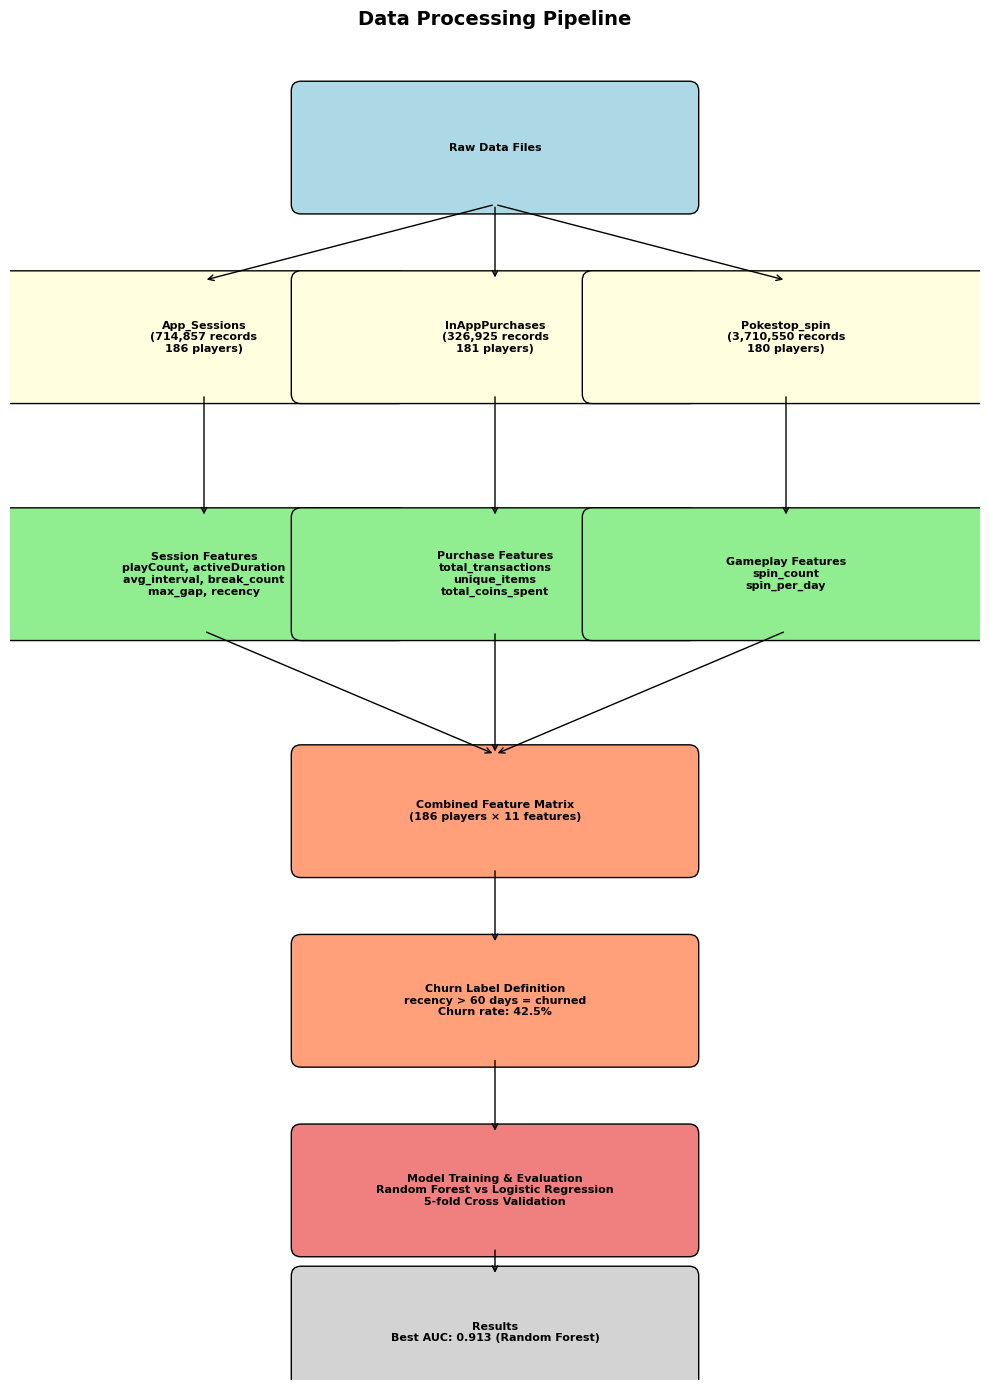

saved as pipeline.png


In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(10, 14))
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis('off')

boxes = [
    (5, 13, 'Raw Data Files', 'lightblue'),
    (2, 11, 'App_Sessions\n(714,857 records\n186 players)', 'lightyellow'),
    (5, 11, 'InAppPurchases\n(326,925 records\n181 players)', 'lightyellow'),
    (8, 11, 'Pokestop_spin\n(3,710,550 records\n180 players)', 'lightyellow'),
    (2, 8.5, 'Session Features\nplayCount, activeDuration\navg_interval, break_count\nmax_gap, recency', 'lightgreen'),
    (5, 8.5, 'Purchase Features\ntotal_transactions\nunique_items\ntotal_coins_spent', 'lightgreen'),
    (8, 8.5, 'Gameplay Features\nspin_count\nspin_per_day', 'lightgreen'),
    (5, 6, 'Combined Feature Matrix\n(186 players × 11 features)', 'lightsalmon'),
    (5, 4, 'Churn Label Definition\nrecency > 60 days = churned\nChurn rate: 42.5%', 'lightsalmon'),
    (5, 2, 'Model Training & Evaluation\nRandom Forest vs Logistic Regression\n5-fold Cross Validation', 'lightcoral'),
    (5, 0.5, 'Results\nBest AUC: 0.913 (Random Forest)', 'lightgray'),
]

for x, y, text, color in boxes:
    ax.add_patch(mpatches.FancyBboxPatch(
        (x-2, y-0.6), 4, 1.2,
        boxstyle="round,pad=0.1",
        facecolor=color, edgecolor='black'
    ))
    ax.text(x, y, text, ha='center', va='center', fontsize=8, fontweight='bold')


arrows = [
    (5, 12.4, 5, 11.6),
    (5, 12.4, 2, 11.6),      # Raw → App
    (5, 12.4, 8, 11.6),      # Raw → Spin
    (2, 10.4, 2, 9.1),       # App → Session features
    (5, 10.4, 5, 9.1),       # IAP → Purchase features
    (8, 10.4, 8, 9.1),       # Spin → Gameplay features
    (2, 7.9, 5, 6.6),        # Session → Combined
    (5, 7.9, 5, 6.6),        # Purchase → Combined
    (8, 7.9, 5, 6.6),        # Gameplay → Combined
    (5, 5.4, 5, 4.6),        # Combined → Churn label
    (5, 3.4, 5, 2.6),        # Churn → Models
    (5, 1.4, 5, 1.1),        # Models → Results
]

for x1, y1, x2, y2 in arrows:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='black'))

plt.title('Data Processing Pipeline', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('pipeline.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved as pipeline.png")

Identify break periods as gaps of more than 7 days between sessions, and calculate their duration.

In [21]:
df['prev_time'] = df.groupby('pid')['Event_time'].shift(1)
df['gap'] = (df['Event_time'] - df['prev_time']).dt.total_seconds() / 86400

# 找break over 7 days
breaks = df[df['gap'] > 7][['pid', 'prev_time', 'Event_time', 'gap']].copy()
breaks.columns = ['pid', 'break_start', 'break_end', 'break_duration']

print("Total breaks found:", len(breaks))
print("Average break duration:", breaks['break_duration'].mean().round(1), "days")
print("\nBreak duration distribution:")
print(breaks['break_duration'].describe())

Total breaks found: 1611
Average break duration: 46.9 days

Break duration distribution:
count    1611.000000
mean       46.896735
std       101.488726
min         7.001817
25%         9.169682
50%        14.551447
75%        30.797066
max      1116.622419
Name: break_duration, dtype: float64


Check how many breaks fall near the 60-day threshold and compare churn counts across different thresholds. This supports the threshold discussion in the dissertation.

In [22]:
print("Break duration:")
print(breaks['break_duration'].describe())


near_60 = breaks[(breaks['break_duration'] >= 50) & (breaks['break_duration'] <= 70)]
print(f"\n between 50-70 days break: {len(near_60)} ({len(near_60)/len(breaks)*100:.1f}%)")

for t in [7, 14, 30, 60, 90]:
    churned = (features_all['recency'] > t).sum()
    print(f"Threshold {t} days: {churned} players churned ({churned/len(features_all)*100:.1f}%)")

Break duration:
count    1611.000000
mean       46.896735
std       101.488726
min         7.001817
25%         9.169682
50%        14.551447
75%        30.797066
max      1116.622419
Name: break_duration, dtype: float64

 between 50-70 days break: 59 (3.7%)
Threshold 7 days: 164 players churned (88.2%)
Threshold 14 days: 129 players churned (69.4%)
Threshold 30 days: 127 players churned (68.3%)
Threshold 60 days: 79 players churned (42.5%)
Threshold 90 days: 79 players churned (42.5%)


Merge player-level features with each observed break to create the dataset for break duration prediction.
Limitation: These features are calculated using each player's full activity history, which may cause some data leakage. This is discussed in the dissertation's Limitations section.

In [23]:
breaks_with_features = breaks.merge(
    features_all[['pid', 'playCount', 'activeDuration', 'avg_interval',
                  'break_count', 'max_gap', 'total_transactions',
                  'unique_items', 'total_coins_spent', 'spin_count', 'spin_per_day']],
    on='pid',
    how='left'
)

print("Shape:", breaks_with_features.shape)
print(breaks_with_features.drop(columns=['pid', 'break_start', 'break_end']).head(3))

Shape: (1611, 14)
   break_duration  playCount  activeDuration  avg_interval  break_count  \
0      779.820359        594     1008.893183      1.701338            3   
1       13.532176        594     1008.893183      1.701338            3   
2       11.057118        594     1008.893183      1.701338            3   

      max_gap  total_transactions  unique_items  total_coins_spent  \
0  779.820359               280.0          21.0             -789.0   
1  779.820359               280.0          21.0             -789.0   
2  779.820359               280.0          21.0             -789.0   

   spin_count  spin_per_day  
0      1112.0      1.108305  
1      1112.0      1.108305  
2      1112.0      1.108305  


Train Random Forest Regressor and Linear Regression to predict break duration. The MAE results are reported in Table VI of the dissertation.

In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
import numpy as np

feature_cols = ['playCount', 'activeDuration', 'avg_interval',
                'break_count', 'max_gap', 'total_transactions',
                'unique_items', 'total_coins_spent', 'spin_count', 'spin_per_day']

X = breaks_with_features[feature_cols].fillna(0)
y = breaks_with_features['break_duration']

# Cross validation
from sklearn.model_selection import KFold
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_scores = cross_val_score(rf_reg, X, y, cv=cv, scoring='neg_mean_absolute_error')
print("Random Forest MAE:", (-rf_scores.mean()).round(1), "±", rf_scores.std().round(1), "days")

# Linear Regression
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
lr_reg = LinearRegression()
lr_scores = cross_val_score(lr_reg, X_scaled, y, cv=cv, scoring='neg_mean_absolute_error')
print("Linear Regression MAE:", (-lr_scores.mean()).round(1), "±", lr_scores.std().round(1), "days")

Random Forest MAE: 44.0 ± 4.4 days
Linear Regression MAE: 46.2 ± 3.6 days


Feature importance for break duration prediction. Used in Table VII of the dissertation.

In [25]:
# features importance
rf_reg.fit(X, y)
importances = pd.Series(rf_reg.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=False)
print("Feature Importance:")
print(importances)

Feature Importance:
max_gap               0.499510
break_count           0.302187
activeDuration        0.035204
total_coins_spent     0.031089
avg_interval          0.029494
spin_per_day          0.023352
unique_items          0.021658
spin_count            0.019696
playCount             0.019175
total_transactions    0.018636
dtype: float64


Remove max_gap and break_count to test their effect on break duration prediction. The result is reported in Table VI of the dissertation.

In [26]:
# remove max_gap and break_count
feature_cols_reduced = ['playCount', 'activeDuration', 'avg_interval',
                        'total_transactions', 'unique_items',
                        'total_coins_spent', 'spin_count', 'spin_per_day']

X_reduced = breaks_with_features[feature_cols_reduced].fillna(0)
y = breaks_with_features['break_duration']

# Random Forest
rf_scores2 = cross_val_score(rf_reg, X_reduced, y, cv=cv, scoring='neg_mean_absolute_error')
print("RF without max_gap & break_count MAE:", (-rf_scores2.mean()).round(1), "±", rf_scores2.std().round(1), "days")

# Linear Regression
X_reduced_scaled = scaler.fit_transform(X_reduced)
lr_scores2 = cross_val_score(lr_reg, X_reduced_scaled, y, cv=cv, scoring='neg_mean_absolute_error')
print("LR without max_gap & break_count MAE:", (-lr_scores2.mean()).round(1), "±", lr_scores2.std().round(1), "days")

RF without max_gap & break_count MAE: 47.1 ± 3.5 days
LR without max_gap & break_count MAE: 47.8 ± 3.0 days


Visualise the distribution of player recency around the 60-day threshold. This supports the threshold discussion in the dissertation.

Players with recency > 60 days (churned): 79
Players with recency <= 60 days (active): 107

Recency distribution:
count    186.000000
mean     111.381250
std      143.792634
min        0.000000
25%       10.086510
50%       43.145897
75%      164.039543
max      998.480336
Name: recency, dtype: float64


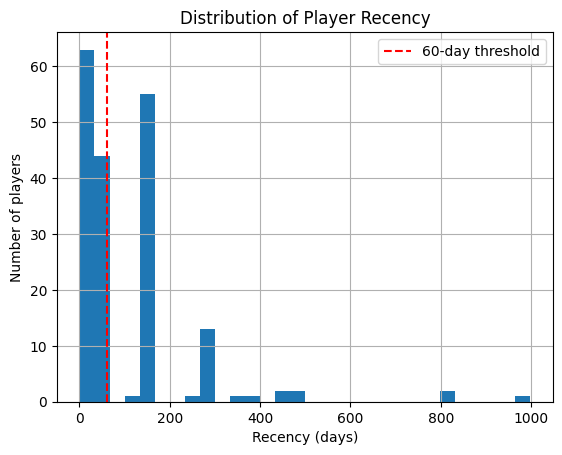

In [27]:
print("Players with recency > 60 days (churned):", (features_all['recency'] > 60).sum())
print("Players with recency <= 60 days (active):", (features_all['recency'] <= 60).sum())
print("\nRecency distribution:")
print(features_all['recency'].describe())


import matplotlib.pyplot as plt
features_all['recency'].hist(bins=30)
plt.axvline(x=60, color='red', linestyle='--', label='60-day threshold')
plt.xlabel('Recency (days)')
plt.ylabel('Number of players')
plt.title('Distribution of Player Recency')
plt.legend()
plt.show()

Final Results
Compare Random Forest, Logistic Regression, and Gradient Boosting across all four feature combinations using the corrected pipeline to avoid data leakage from feature scaling. These are the final AUC results reported in Table IV of the dissertation.

In [28]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

# fixed CV
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# models
rf_final = RandomForestClassifier(n_estimators=100, random_state=42)
gb_final = GradientBoostingClassifier(n_estimators=100, random_state=42)
lr_pipeline_final = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000))
])

print("=== final results ===")

# Session only
X1 = features_all[['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap']].fillna(0)
y = features_all['churn']
rf_s = cross_val_score(rf_final, X1, y, cv=cv_final, scoring='roc_auc').mean()
lr_s = cross_val_score(lr_pipeline_final, X1, y, cv=cv_final, scoring='roc_auc').mean()
gb_s = cross_val_score(gb_final, X1, y, cv=cv_final, scoring='roc_auc').mean()
print(f"Session only - RF: {rf_s:.3f}, LR: {lr_s:.3f}, GB: {gb_s:.3f}")

# Session + Spin
X2 = features_all[['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap', 'spin_count', 'spin_per_day']].fillna(0)
rf_s = cross_val_score(rf_final, X2, y, cv=cv_final, scoring='roc_auc').mean()
lr_s = cross_val_score(lr_pipeline_final, X2, y, cv=cv_final, scoring='roc_auc').mean()
gb_s = cross_val_score(gb_final, X2, y, cv=cv_final, scoring='roc_auc').mean()
print(f"Session + Spin - RF: {rf_s:.3f}, LR: {lr_s:.3f}, GB: {gb_s:.3f}")

# Session + Purchase
X3 = features_all[['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap', 'total_transactions', 'unique_items', 'total_coins_spent']].fillna(0)
rf_s = cross_val_score(rf_final, X3, y, cv=cv_final, scoring='roc_auc').mean()
lr_s = cross_val_score(lr_pipeline_final, X3, y, cv=cv_final, scoring='roc_auc').mean()
gb_s = cross_val_score(gb_final, X3, y, cv=cv_final, scoring='roc_auc').mean()
print(f"Session + Purchase - RF: {rf_s:.3f}, LR: {lr_s:.3f}, GB: {gb_s:.3f}")

# Session + Purchase + Spin
X4 = features_all[['playCount', 'activeDuration', 'avg_interval', 'break_count', 'max_gap', 'total_transactions', 'unique_items', 'total_coins_spent', 'spin_count', 'spin_per_day']].fillna(0)
rf_s = cross_val_score(rf_final, X4, y, cv=cv_final, scoring='roc_auc').mean()
lr_s = cross_val_score(lr_pipeline_final, X4, y, cv=cv_final, scoring='roc_auc').mean()
gb_s = cross_val_score(gb_final, X4, y, cv=cv_final, scoring='roc_auc').mean()
print(f"Session + Purchase + Spin - RF: {rf_s:.3f}, LR: {lr_s:.3f}, GB: {gb_s:.3f}")

=== final results ===
Session only - RF: 0.870, LR: 0.669, GB: 0.862
Session + Spin - RF: 0.872, LR: 0.670, GB: 0.873
Session + Purchase - RF: 0.903, LR: 0.651, GB: 0.903
Session + Purchase + Spin - RF: 0.913, LR: 0.667, GB: 0.904


Final AUC comparison chart using the results above. Used as Fig. 3 in the dissertation and in the presentation.

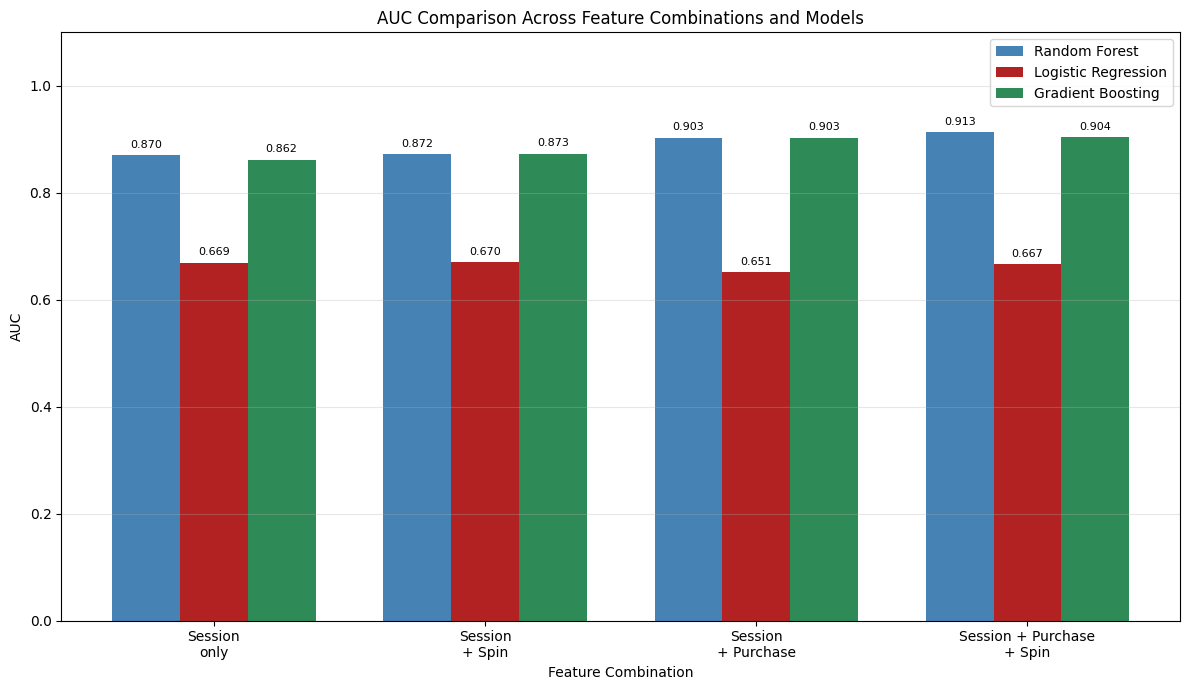

saved！


In [29]:

import matplotlib.pyplot as plt
import numpy as np

feature_combinations = ['Session\nonly', 'Session\n+ Spin', 'Session\n+ Purchase', 'Session + Purchase\n+ Spin']

rf_aucs = [0.870, 0.872, 0.903, 0.913]
lr_aucs = [0.669, 0.670, 0.651, 0.667]
gb_aucs = [0.862, 0.873, 0.903, 0.904]

x = np.arange(len(feature_combinations))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 7))

bars1 = ax.bar(x - width, rf_aucs, width, label='Random Forest', color='steelblue')
bars2 = ax.bar(x, lr_aucs, width, label='Logistic Regression', color='firebrick')
bars3 = ax.bar(x + width, gb_aucs, width, label='Gradient Boosting', color='seagreen')

ax.set_xlabel('Feature Combination')
ax.set_ylabel('AUC')
ax.set_title('AUC Comparison Across Feature Combinations and Models')
ax.set_xticks(x)
ax.set_xticklabels(feature_combinations)
ax.set_ylim(0, 1.1)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

for bar in [*bars1, *bars2, *bars3]:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('auc_comparison_final.png', dpi=150, bbox_inches='tight')
plt.show()
print("saved！")

Final feature importance for churn prediction using all 10 features (AUC = 0.913). Used in Table V and Fig. 4 of the dissertation.

Final Feature Importance (Churn Prediction):
activeDuration        0.3644
playCount             0.0969
avg_interval          0.0903
unique_items          0.0850
total_coins_spent     0.0829
total_transactions    0.0685
spin_per_day          0.0644
spin_count            0.0588
max_gap               0.0584
break_count           0.0304
dtype: float64


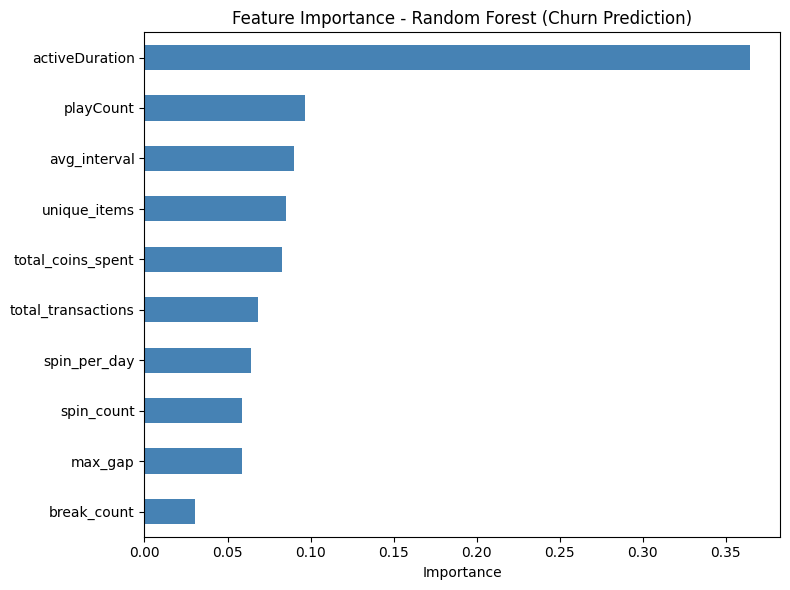

In [30]:
# final Feature Importance (Session + Purchase + Spin, threshold 60-day)
feature_cols_final = ['playCount', 'activeDuration', 'avg_interval',
                      'break_count', 'max_gap', 'total_transactions',
                      'unique_items', 'total_coins_spent',
                      'spin_count', 'spin_per_day']

X_final = features_all[feature_cols_final].fillna(0)
y_final = features_all['churn']

rf_final = RandomForestClassifier(n_estimators=100, random_state=42)
rf_final.fit(X_final, y_final)

importances = pd.Series(rf_final.feature_importances_, index=feature_cols_final)
importances = importances.sort_values(ascending=False)

print("Final Feature Importance (Churn Prediction):")
print(importances.round(4))

# plot
importances.sort_values().plot(kind='barh', figsize=(8, 6), color='steelblue')
plt.title('Feature Importance - Random Forest (Churn Prediction)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance_final.png', dpi=150, bbox_inches='tight')
plt.show()

Final classification report for the churn model, including precision, recall, and F1-score. Used in Table IX of the dissertation.

In [31]:

from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_predict

feature_cols_final = ['playCount', 'activeDuration', 'avg_interval',
                      'break_count', 'max_gap', 'total_transactions',
                      'unique_items', 'total_coins_spent',
                      'spin_count', 'spin_per_day']

X_final = features_all[feature_cols_final].fillna(0)
y_final = features_all['churn']

# fixed CV
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest
rf_final = RandomForestClassifier(n_estimators=100, random_state=42)
y_pred_rf = cross_val_predict(rf_final, X_final, y_final, cv=cv_final)

print("=== Random Forest Classification Report ===")
print(classification_report(y_final, y_pred_rf, target_names=['Active', 'Churned']))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

      Active       0.87      0.84      0.86       107
     Churned       0.80      0.84      0.81        79

    accuracy                           0.84       186
   macro avg       0.83      0.84      0.84       186
weighted avg       0.84      0.84      0.84       186

